Dataset Analysis

In [1]:
# Installs

# If necessary:
# pip install pandas numpy scipy matplotlib seaborn networkx scikit-learn pathlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from collections import Counter
from scipy import sparse
from scipy.stats import pearsonr
from pathlib import Path

In [2]:
# Data Imports

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATA_DIR = PROJECT_ROOT / "Data" / "ml-32m"

RATINGS_FILE = DATA_DIR / "ratings.csv"
MOVIES_FILE = DATA_DIR / "movies.csv"
LINKS_FILE = DATA_DIR / "links.csv"
TAGS_FILE = DATA_DIR / "tags.csv"

**Basics**

In [3]:
movies = pd.read_csv(MOVIES_FILE)
tags = pd.read_csv(TAGS_FILE)

print("Movies:")
print(movies.shape)
print(movies.head())

print("\nTags:")
print(tags.shape)
print(tags.head())

Movies:
(87585, 3)
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  

Tags:
(2000072, 4)
   userId  movieId          tag   timestamp
0      22    26479  Kevin Kline  1583038886
1      22    79592     misogyny  1581476297
2      22   247150   acrophobia  1622483469
3      34     2174        music  1249808064
4      34     2174        weird  1249808102


In [4]:
rating_rows = 0
rating_min = np.inf
rating_max = -np.inf
user_ids = set()
movie_ids = set()
rating_counts = Counter()

for chunk in pd.read_csv(RATINGS_FILE, usecols=["userId", "movieId", "rating"], chunksize=1_000_000):
    rating_rows += len(chunk)
    rating_min = min(rating_min, chunk["rating"].min())
    rating_max = max(rating_max, chunk["rating"].max())
    user_ids.update(chunk["userId"].unique())
    movie_ids.update(chunk["movieId"].unique())
    rating_counts.update(chunk["rating"].value_counts().to_dict())

print("Number of ratings:", rating_rows)
print("Number of users:", len(user_ids))
print("Number of movies rated:", len(movie_ids))
print("Minimum rating:", rating_min)
print("Maximum rating:", rating_max)

Number of ratings: 32000204
Number of users: 200948
Number of movies rated: 84432
Minimum rating: 0.5
Maximum rating: 5.0


**Rating Distribution**

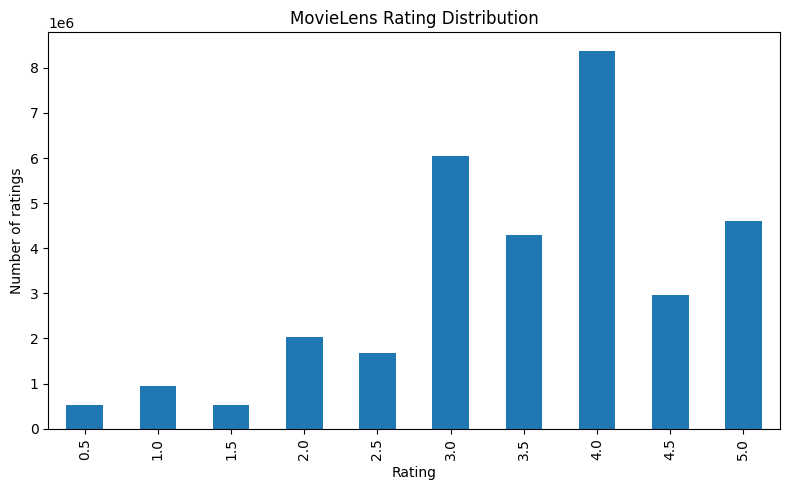

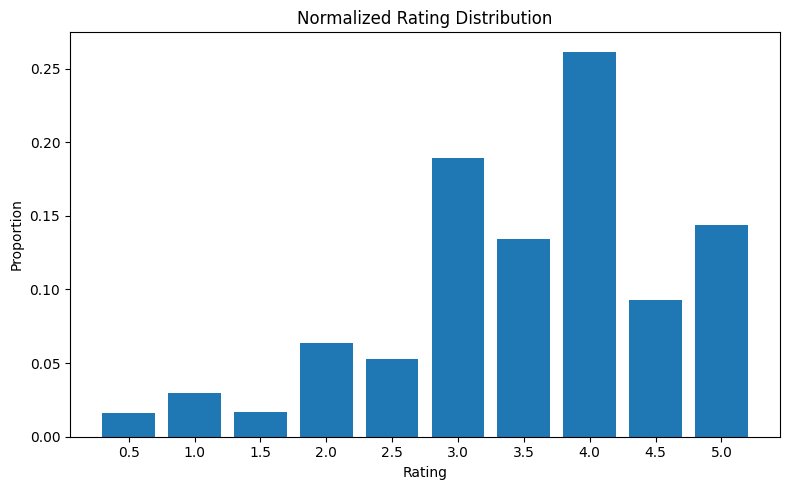

In [5]:
rating_distribution = pd.Series(rating_counts).sort_index()

plt.figure(figsize=(8, 5))
rating_distribution.plot(kind="bar")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("MovieLens Rating Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
rating_distribution / rating_distribution.sum()
plt.bar(rating_distribution.index.astype(str), rating_distribution.values / rating_distribution.sum())
plt.xlabel("Rating")
plt.ylabel("Proportion")
plt.title("Normalized Rating Distribution")
plt.tight_layout()
plt.show()

**Link Density**

In [6]:
user_degree = Counter()
movie_degree = Counter()

for chunk in pd.read_csv(RATINGS_FILE, usecols=["userId", "movieId"], chunksize=1_000_000):
    user_counts = chunk["userId"].value_counts()
    movie_counts = chunk["movieId"].value_counts()
    for uid, count in user_counts.items():
        user_degree[uid] += count
    for mid, count in movie_counts.items():
        movie_degree[mid] += count

user_deg = np.array(list(user_degree.values()))
movie_deg = np.array(list(movie_degree.values()))

N_users = len(user_deg)
N_movies = len(movie_deg)
N = N_users + N_movies
L = user_deg.sum()
p = L / (N_users * N_movies)

all_degrees = np.concatenate([user_deg, movie_deg])
degree_mean = all_degrees.mean()
degree_std = all_degrees.std()

print("Number of users:", N_users)
print("Number of movies:", N_movies)
print("Total nodes N:", N)
print("Number of links L:", L)
print("Bipartite link density p:", p)
print("Mean degree:", degree_mean)
print("Degree standard deviation:", degree_std)

Number of users: 200948
Number of movies: 84432
Total nodes N: 285380
Number of links L: 32000204
Bipartite link density p: 0.0018860881306254364
Mean degree: 224.26381666549864
Degree standard deviation: 1433.3284129334093


In [7]:
print("USER DEGREE")
print("----------------")
print("Mean:", user_deg.mean())
print("Median:", np.median(user_deg))
print("Std:", user_deg.std())
print("Min:", user_deg.min())
print("Max:", user_deg.max())

print("\nMOVIE DEGREE")
print("----------------")
print("Mean:", movie_deg.mean())
print("Median:", np.median(movie_deg))
print("Std:", movie_deg.std())
print("Min:", movie_deg.min())
print("Max:", movie_deg.max())

USER DEGREE
----------------
Mean: 159.24619304496684
Median: 73.0
Std: 282.02476057052786
Min: 20
Max: 33332

MOVIE DEGREE
----------------
Mean: 379.0056376729202
Median: 5.0
Std: 2592.4244385792053
Min: 1
Max: 102929


**Degree distribution**

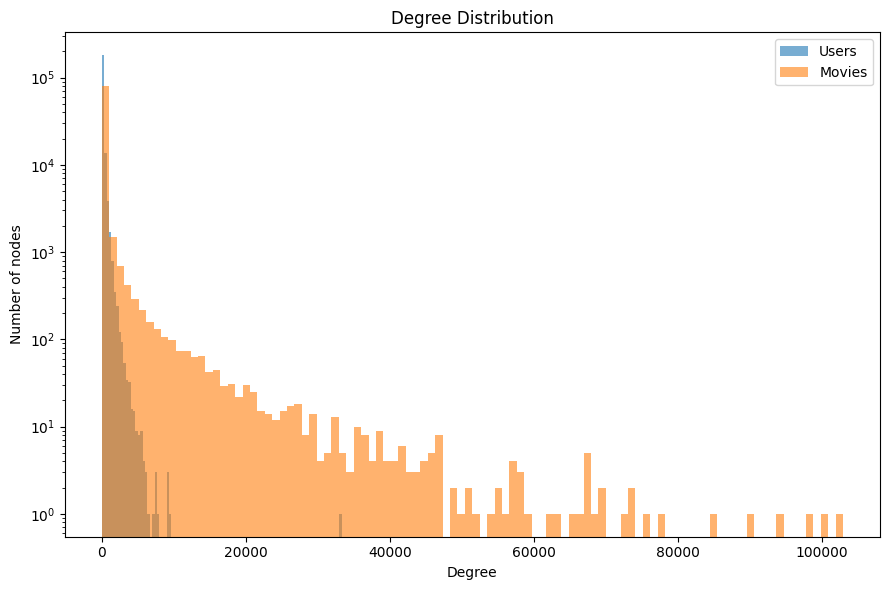

In [8]:
# Linear

plt.figure(figsize=(9, 6))
plt.hist(user_deg, bins=100, alpha=0.6, log=True, label="Users")
plt.hist(movie_deg, bins=100, alpha=0.6, log=True, label="Movies")
plt.xlabel("Degree")
plt.ylabel("Number of nodes")
plt.title("Degree Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
def degree_distribution(degrees):
    counts = Counter(degrees)
    k = np.array(sorted(counts.keys()))
    n = np.array([counts[x] for x in k])
    probability = n / n.sum()
    return k, probability

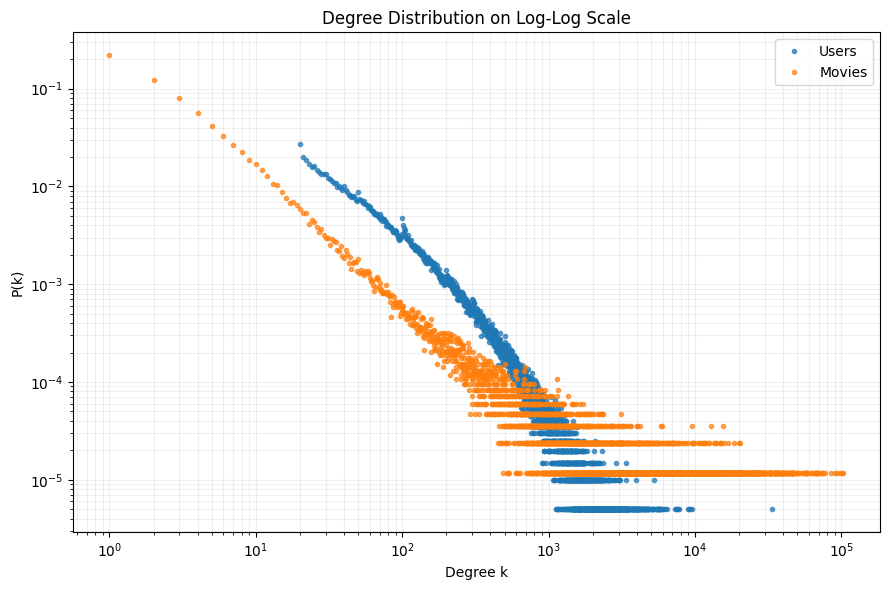

In [10]:
# Log-Log

k_users, pk_users = degree_distribution(user_deg)
k_movies, pk_movies = degree_distribution(movie_deg)

plt.figure(figsize=(9, 6))
plt.loglog(k_users, pk_users, marker="o", linestyle="none", markersize=3, alpha=0.7, label="Users")
plt.loglog(k_movies, pk_movies, marker="o", linestyle="none", markersize=3, alpha=0.7, label="Movies")
plt.xlabel("Degree k")
plt.ylabel("P(k)")
plt.title("Degree Distribution on Log-Log Scale")
plt.legend()
plt.grid(True, which="both", alpha=0.2)
plt.tight_layout()
plt.show()

**Coefficient of Variation**

In [11]:
cv_users = user_deg.std() / user_deg.mean()
cv_movies = movie_deg.std() / movie_deg.mean()

print("User CV:", cv_users)
print("Movie CV:", cv_movies)

User CV: 1.7709984469826017
Movie CV: 6.840068275755976


In [12]:
print("Users")
print("Observed mean:", user_deg.mean())
print("Observed std:", user_deg.std())
print("Poisson expected std:", np.sqrt(user_deg.mean()))

print("\nMovies")
print("Observed mean:", movie_deg.mean())
print("Observed std:", movie_deg.std())
print("Poisson expected std:", np.sqrt(movie_deg.mean()))

Users
Observed mean: 159.24619304496684
Observed std: 282.02476057052786
Poisson expected std: 12.619278626172212

Movies
Observed mean: 379.0056376729202
Observed std: 2592.4244385792053
Poisson expected std: 19.46806712729644


**Power law Tail**

In [13]:
def plot_tail(degrees, title):
    counts = Counter(degrees)
    k = np.array(sorted(counts.keys()))
    n = np.array([counts[x] for x in k])
    pk = n / n.sum()
    mask = k >= np.percentile(k, 70)

    plt.figure(figsize=(8, 6))
    plt.loglog(k[mask], pk[mask], "o", markersize=4)
    plt.xlabel("Degree k")
    plt.ylabel("P(k)")
    plt.title(title)
    plt.grid(True, which="both", alpha=0.2)
    plt.show()

def estimate_powerlaw_exponent(degrees, xmin):
    tail = degrees[degrees >= xmin]
    gamma = 1 + len(tail) / np.sum(np.log(tail / xmin))
    return gamma, len(tail)

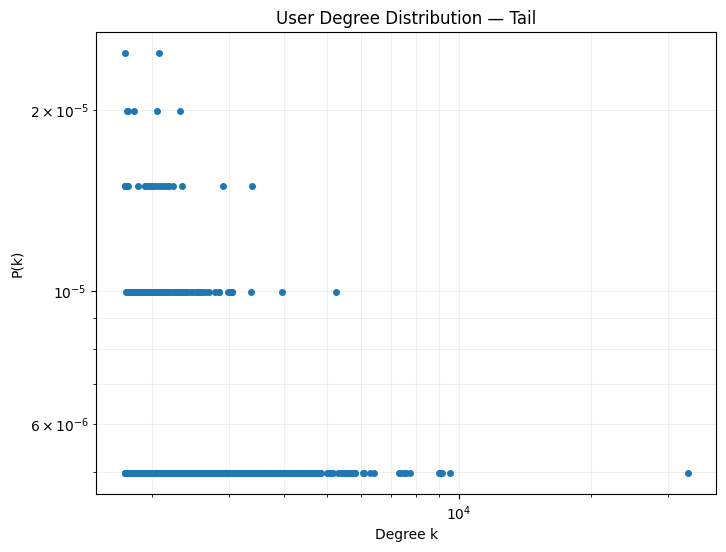

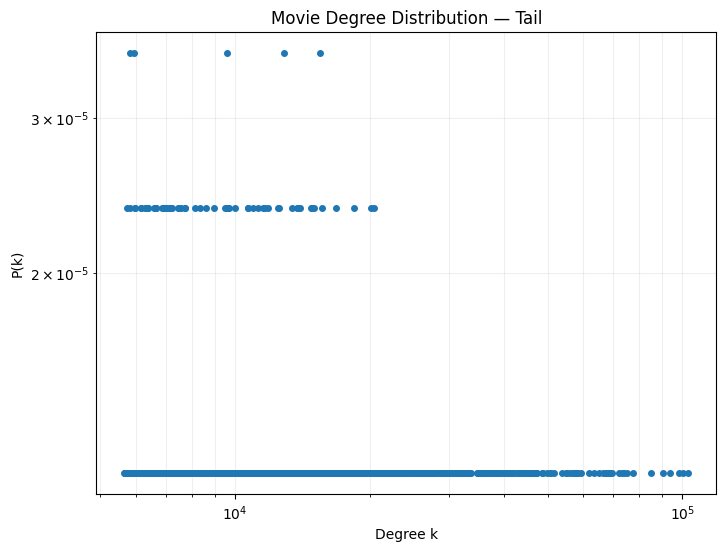

In [14]:
plot_tail(user_deg, "User Degree Distribution — Tail")
plot_tail(movie_deg, "Movie Degree Distribution — Tail")

In [15]:
xmin_users = np.percentile(user_deg, 90)
xmin_movies = np.percentile(movie_deg, 90)

gamma_users, n_users_tail = estimate_powerlaw_exponent(user_deg, xmin_users)
gamma_movies, n_movies_tail = estimate_powerlaw_exponent(movie_deg, xmin_movies)

print("Users:")
print("xmin =", xmin_users)
print("gamma =", gamma_users)
print("Tail observations =", n_users_tail)

print("\nMovies:")
print("xmin =", xmin_movies)
print("gamma =", gamma_movies)
print("Tail observations =", n_movies_tail)

Users:
xmin = 364.0
gamma = 2.7309965711227235
Tail observations = 20109

Movies:
xmin = 248.90000000000873
gamma = 1.5826389048931246
Tail observations = 8444


Top movies by Degree

In [16]:
movie_degrees_df = pd.DataFrame({"movieId": list(movie_degree.keys()), "degree": list(movie_degree.values())})
movie_degrees_df = movie_degrees_df.merge(movies[["movieId", "title"]], on="movieId", how="left")

print(movie_degrees_df.sort_values("degree", ascending=False).head(20))

    movieId  degree                                              title
0       318  102929                   Shawshank Redemption, The (1994)
1       356  100296                                Forrest Gump (1994)
2       296   98409                                Pulp Fiction (1994)
3      2571   93808                                 Matrix, The (1999)
4       593   90330                   Silence of the Lambs, The (1991)
5       260   85010          Star Wars: Episode IV - A New Hope (1977)
6      2959   77332                                  Fight Club (1999)
7       480   75233                               Jurassic Park (1993)
10      527   73849                            Schindler's List (1993)
8      4993   73122  Lord of the Rings: The Fellowship of the Ring,...
9      1196   72151  Star Wars: Episode V - The Empire Strikes Back...
13      110   69482                                  Braveheart (1995)
11        1   68997                                   Toy Story (1995)
12    

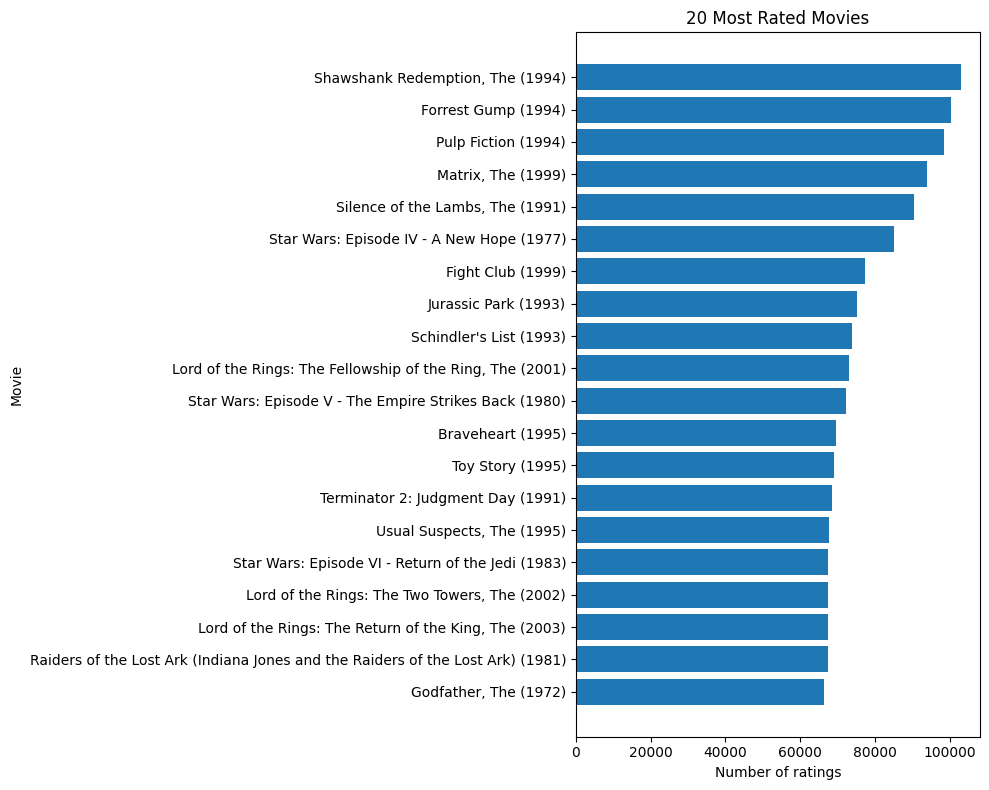

In [17]:
# Top 20

top_movies = (movie_degrees_df.sort_values("degree", ascending=False).head(20).sort_values("degree"))

plt.figure(figsize=(10, 8))
plt.barh(top_movies["title"], top_movies["degree"])
plt.xlabel("Number of ratings")
plt.ylabel("Movie")
plt.title("20 Most Rated Movies")
plt.tight_layout()
plt.show()

**Degree correlation (assortativity)**

In [18]:
sum_x = 0.0
sum_y = 0.0
sum_x2 = 0.0
sum_y2 = 0.0
sum_xy = 0.0
M = 0

for chunk in pd.read_csv(RATINGS_FILE, usecols=["userId", "movieId"], chunksize=1_000_000):
    u = chunk["userId"].map(user_degree).to_numpy(dtype=float)
    v = chunk["movieId"].map(movie_degree).to_numpy(dtype=float)
    sum_x += u.sum()
    sum_y += v.sum()
    sum_x2 += np.sum(u * u)
    sum_y2 += np.sum(v * v)
    sum_xy += np.sum(u * v)
    M += len(chunk)

mean_x = sum_x / M
mean_y = sum_y / M
cov_xy = sum_xy / M - mean_x * mean_y
var_x = sum_x2 / M - mean_x**2
var_y = sum_y2 / M - mean_y**2
assortativity = cov_xy / np.sqrt(var_x * var_y)

print("Degree assortativity:", assortativity)

Degree assortativity: -0.1732645370926956
